# Evaluation of rotational phantom data acquired using a sequence output by SIEMENS vendor PC-MRI sequence

### Necessary imports including mapvbvd to read in SIEMENS raw data

In [213]:
import os
import string
import re
import copy

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as patches
import matplotlib.patheffects as PathEffects
from scipy import ndimage
import cv2

import mapvbvd
from pint import Quantity
# import nibabel as nib

### Geometrical data

In [214]:
# phantom radius
r_phan = Quantity(6.3, 'cm')

filetype = '.svg'

### Load raw data

We load the file unsorted, which means we get dimensions [x, coils, others], where others include phase encodings, averages etc. By reshaping according to loop structure, the raw data has the correct dimensions.
Here, we assume a square image dimension and 4 flow encodings.

In [215]:
# Define the path and dataset number

# 200rpm, venc 150
# high BW
# data_file_path = r'meas_MID00107_FID06053_23_cor_venc150_200rpm_135cms_10avgs_dir1.npy'
# data_file_path = r'meas_MID00117_FID06063_33_cor_venc150_200rpm_135cms_10avgs_dir2.npy'


# low BW
# dir = 2
# venc = 100
# rpm = 100
# data_file_path = r'./data/ccw_100_venc100.npy'
# dir = 2
# venc = 150
# rpm = 200
# data_file_path = r'./data/ccw_200.npy'
# dir = 2
# venc = 250
# rpm = 300
# data_file_path = r'./data/ccw_300.npy'
# dir = 2
# venc = 300
# rpm = 400
# data_file_path = r'./data/ccw_400.npy'
# dir = 2
# venc = 400
# rpm = 500
# data_file_path = r'./data/ccw_500.npy'

# dir = 1
# venc = 100
# rpm = 100
# data_file_path = r'./data/cw_100_venc100.npy'
# dir = 1
# venc = 150
# rpm = 200
# data_file_path = r'./data/cw_200.npy'
# dir = 1
# venc = 250
# rpm = 300
# data_file_path = r'./data/cw_300.npy'
# dir = 1
# venc = 300
# rpm = 400
# data_file_path = r'./data/cw_400.npy'
# dir = 1
# venc = 400
# rpm = 500
# data_file_path = r'./data/cw_500.npy'

# # high BW
# dir = 2
# venc = 100
# rpm = 100
# data_file_path = r'./data/ccw_100_venc100_fast.npy'
# dir = 2
# venc = 150
# rpm = 200
# data_file_path = r'./data/ccw_200_fast.npy'
# dir = 2
# venc = 250
# rpm = 300
# data_file_path = r'./data/ccw_300_fast.npy'
# dir = 2
# venc = 300
# rpm = 400
# data_file_path = r'./data/ccw_400_fast.npy'
# dir = 2
# venc = 400
# rpm = 500
# data_file_path = r'./data/ccw_500_fast.npy'

# dir = 1
# venc = 100
# rpm = 100
# data_file_path = r'./data/cw_100_venc100_fast.npy'
# dir = 1
# venc = 150
# rpm = 200
# data_file_path = r'./data/cw_200_fast.npy'
# dir = 1
# venc = 250
# rpm = 300
# data_file_path = r'./data/cw_300_fast.npy'
# dir = 1
# venc = 300
# rpm = 400
# data_file_path = r'./data/cw_400_fast.npy'
# dir = 1
# venc = 400
# rpm = 500
# data_file_path = r'./data/cw_500_fast.npy'


# 200rpm, venc 150
# low BW
# data_file_path = r'meas_MID00108_FID06054_24cor_venc150_200rpm_135cms_10avgs_dir1.npy'
# data_file_path = r'meas_MID00118_FID06064_34cor_venc150_200rpm_135cms_10avgs_dir2.npy'

# # 400rpm, venc 300
# # high BW
# data_file_path = r'meas_MID00113_FID06059_29_cor_venc300_400rpm_135cms_10avgs_dir1.npy'
# data_file_path = r'meas_MID00121_FID06067_37_cor_venc300_400rpm_135cms_10avgs_dir2.npy'

# # 400rpm, venc 300
# # low BW
# data_file_path = r'meas_MID00114_FID06060_30_cor_venc300_400rpm_135cms_10avgs_dir1.npy'
# data_file_path = r'meas_MID00122_FID06068_38_cor_venc300_400rpm_135cms_10avgs_dir2.npy'



# dir = 1
# venc = 50
# rpm = 50
# data_file_path = r'meas_MID00045_FID16508_BEAT_FQ_venc50_BW446_dyn32_rpm50_dir1.npy'

# dir = 1
# venc = 200
# rpm = 200
# data_file_path = r'meas_MID00083_FID16546_BEAT_FQ_venc200_BW893_dyn16_rpm200_dir1.npy'

# dir = 1
# venc = 500
# rpm = 500
# data_file_path = r'meas_MID00176_FID16639_BEAT_FQ_venc500_BW893_dyn16_rpm500_dir1.npy'

dir = 2
venc = 500
rpm = 500
data_file_path = r'meas_MID00206_FID16669_BEAT_FQ_venc500_BW893_dyn16_rpm500_dir2.npy'

filename = Path(data_file_path).stem
data = np.load(data_file_path)

mag = np.abs(data[:, :, 0])
velx = np.angle(data[:, :, 1] / data[:, :, 0])
vely = np.angle(data[:, :, 2] / data[:, :, 0])
velz = np.angle(data[:, :, 3] / data[:, :, 0])

velx = venc * velx / np.pi
vely = venc * vely / np.pi
velz = venc * velz / np.pi

data = np.stack((mag, velz, velx, vely), axis=-1)

# data = nib.load(data_file_path).get_fdata()

# # raw
# venc = re.search(r'venc(\d+)', data_file_path)
# if venc is None:
#     venc = 100
# else:
#     venc = float(venc.group(1))
    
# rpm = re.search(r'(\d+)rpm', data_file_path)
# if rpm is None:
#     rpm = 0
# else:
#     rpm = float(rpm.group(1))
    
# dir = re.search(r'dir(\d+)', data_file_path)
# if dir is None:
#     dir = 0
# else:
#     dir = float(dir.group(1))
    
    
venc_lims = (-venc, venc)
venc_ticks = np.arange(-venc, venc*1.1, venc/2)

venc_abs_lims = (0, venc)
venc_abs_ticks = np.arange(0, venc*1.1, venc/2)

diff_fac = 0.1
venc_diff_lims = (-diff_fac*venc, diff_fac*venc)
venc_diff_ticks = np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)

# venc_abs_diff_lims = (0, diff_fac*venc)
# venc_abs_diff_ticks = np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)

ec_fac = 0.4
venc_ec_lims = (-ec_fac*venc, ec_fac*venc)
# venc_ec_ticks = np.arange(-0.1*venc, venc*0.51, venc/20)
venc_ec_ticks = np.arange(-ec_fac*venc, ec_fac*venc*1.1, ec_fac*venc/2)

In [216]:
print(f'Loaded data with dimensions {data.shape} and venc {venc}, rpm {rpm}, dir {dir}.')

Loaded data with dimensions (224, 225, 4) and venc 500, rpm 500, dir 2.


### Fit circular mask

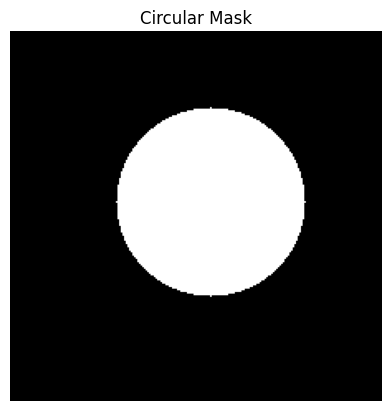

In [217]:
# dicom
mag = data[:, :, 0]
# raw
# mag = np.abs(data[:, :, 1])

# Optional: Blur to reduce noise
norm_img = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
gray = norm_img.astype(np.uint8)

blurred = cv2.GaussianBlur(gray, (9, 9), 2)

# Detect circles using Hough Circle Transform
circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=100,
                           param1=50, param2=30, minRadius=0, maxRadius=0)

# Create an empty mask
mask = np.zeros_like(mag)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    # Assuming we want the first detected circle
    x, y, r = circles[0]
    # Draw the mask
    cv2.circle(mask, (x, y), r, 255, thickness=-1)  # Filled circle

    # Optional: show or save the mask
    plt.imshow(mask, cmap='gray')
    plt.title('Circular Mask')
    plt.axis('off')
    plt.show()

mask = mask / 255.

### Fit elliptical mask

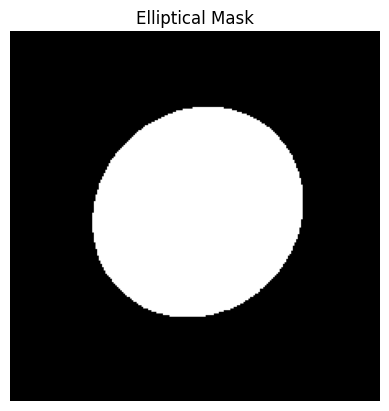

120.55010986328125 133.05604553222656
Eccentricity 0.423
Ratio 0.906


In [218]:
# dicom
mag = data[:, :, 0]
# raw
# mag = np.abs(data[:, :, 1])

# Normalize magnitude for better contrast
norm_img = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
gray = norm_img.astype(np.uint8)

# Thresholding: You can adjust threshold value depending on your data
_, threshed = cv2.threshold(gray, 70, 255, cv2.THRESH_BINARY)

# Optional: Blur to reduce noise
# threshed = cv2.GaussianBlur(threshed, (1, 1), 2)

# Find contours
cnts, _ = cv2.findContours(threshed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create an empty mask
ellipse_mask = np.zeros_like(mag, dtype=np.uint8)

if cnts:
    # Optionally: choose the largest contour
    cnt = max(cnts, key=cv2.contourArea)

    if len(cnt) >= 5:  # fitEllipse requires at least 5 points
        ellipse = cv2.fitEllipse(cnt)

        # Draw the ellipse onto the mask
        cv2.ellipse(ellipse_mask, ellipse, 255, thickness=-1)

        # Show the result
        plt.imshow(ellipse_mask, cmap='gray', aspect=data.shape[1]/data.shape[0])
        plt.title('Elliptical Mask')
        plt.axis('off')
        plt.show()
    else:
        print("Not enough points to fit an ellipse.")
else:
    print("No contours found.")

ellipse_mask = ellipse_mask / np.max(ellipse_mask[:])

(x, y), (major_axis, minor_axis), angle = ellipse
print(major_axis, minor_axis)
eccentricity = np.sqrt(1 - (major_axis / minor_axis)**2)
print(f'Eccentricity {eccentricity:.3f}')
ratio = major_axis / minor_axis
print(f'Ratio {ratio:.3f}')

### Find center of mass of the image (for the zero velocity case)

In [219]:
centre = np.int64(np.round(ndimage.center_of_mass(ellipse_mask)))
print(centre)

# shift the center by integer offset
offset = centre - tuple(ti//2 for ti in data.shape[0:2])

print(f'Shifting image by {offset[0]} and {offset[1]} pixels.')

# dicom
# offset[0] = -offset[0] - 3
# offset[1] = -offset[1] + 3

# raw
# offset[0] = -offset[0] + 1
# offset[1] = -offset[1] - 1

# offset[0] = 0
# offset[1] = 0

print(offset)
# for plotting hlines and vlines later
center_new = tuple(ti//2 for ti in data.shape[0:2]) - offset

center_img = np.int64(center_new)
# shift center such that coordinates resemble MR coordinate system
center_new = np.int64(center_new - (data.shape[0]/2, data.shape[1]/2))

# data = np.take(data, [0, 1, 3, 2], axis=-1)
# mag = np.mean(np.abs(data), axis=2)
mag = np.abs(data[:, :, 0])

data = np.take(data, [0, 1, 3, 2], axis=-1)
# dicom
velx = data[:, :, 1]
vely = data[:, :, 2]
velz = data[:, :, 3]

# raw
# velx = np.angle(data[:, :, 1] / data[:, :, 0])
# vely = np.angle(data[:, :, 2] / data[:, :, 0])
# velz = np.angle(data[:, :, 3] / data[:, :, 0])
# velx = venc * velx / np.pi
# vely = venc * vely / np.pi
# velz = venc * velz / np.pi



[109 114]
Shifting image by -3 and 2 pixels.
[-3  2]


In [220]:
cmap = matplotlib.colormaps.get_cmap('twilight')  # viridis is the default colormap for imshow

# Number of colors to sample
N = 256
# Convert to a list of colors
colors = cmap(np.linspace(0, 1, N))

# Shift the colormap by 0.5 (center goes to the ends)
shifted_colors = np.roll(colors, N // 2, axis=0)

# Create a new colormap
shifted_cmap = LinearSegmentedColormap.from_list('shifted_twilight', shifted_colors)

cmap = shifted_cmap
# cmap.set_bad(color='white')
cmap.set_bad(color=cmap(0.5))

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


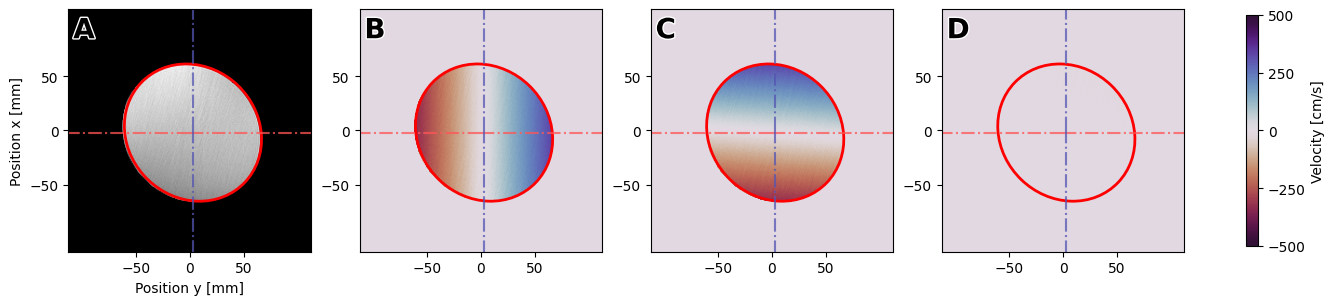

In [221]:
vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(mag * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(velx * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(vely * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow(velz * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow' + filetype)

plt.show()

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


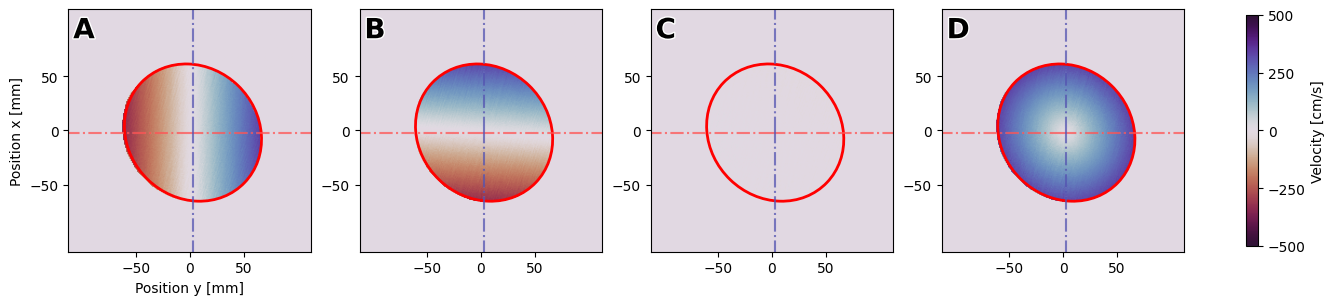

In [222]:
vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(velx * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(vely * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(velz * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow(vel_mag * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow_velmag' + filetype)

plt.show()

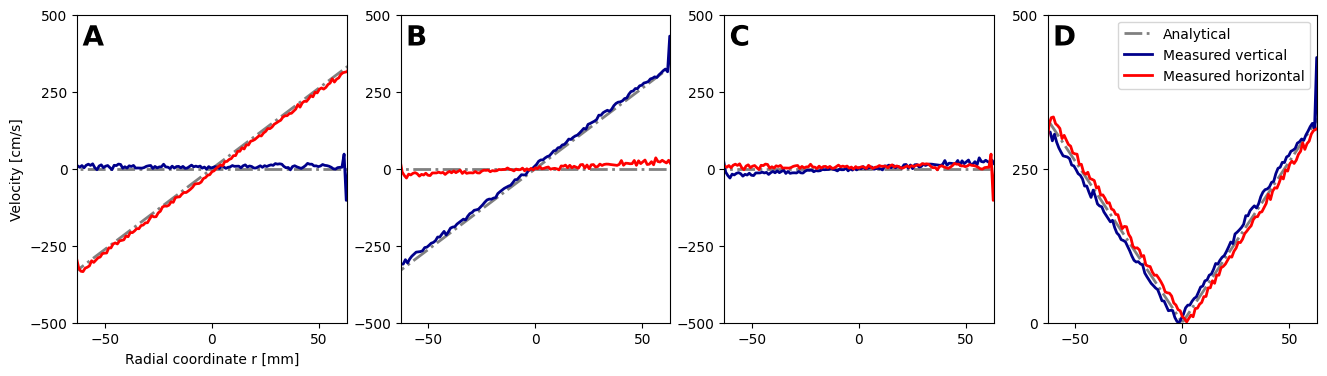

In [223]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

axes[0].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical')
axes[0].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical')
axes[0].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[0].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[0].set_yticks(venc_ticks)

axes[1].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec2, np.zeros_like(r_vec2), color='gray', linestyle='-.', linewidth=2, label='Analytical')
axes[1].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[1].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[1].set_yticks(venc_ticks)

axes[2].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical')
axes[2].plot(r_vec2, vely[center_img[1], :], color='darkblue', linewidth=2, label='Measured vertical')
axes[2].plot(r_vec, velx[:, center_img[0]], color='red', linewidth=2, label='Measured horizontal')
axes[2].set_yticks(venc_ticks)
axes[2].set_ylim(venc_lims)

axes[3].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical')
axes[3].plot(r_vec, np.abs(vely[:, center_img[0]]), color='darkblue', linewidth=2, label='Measured vertical')
axes[3].plot(r_vec2, np.abs(velx[center_img[1], :]), color='red', linewidth=2, label='Measured horizontal')
axes[3].set_ylim(venc_abs_lims)
axes[3].set_yticks(venc_abs_ticks)

axes[0].set_ylabel('Velocity [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

plt.savefig(filename + '_vel' + filetype)

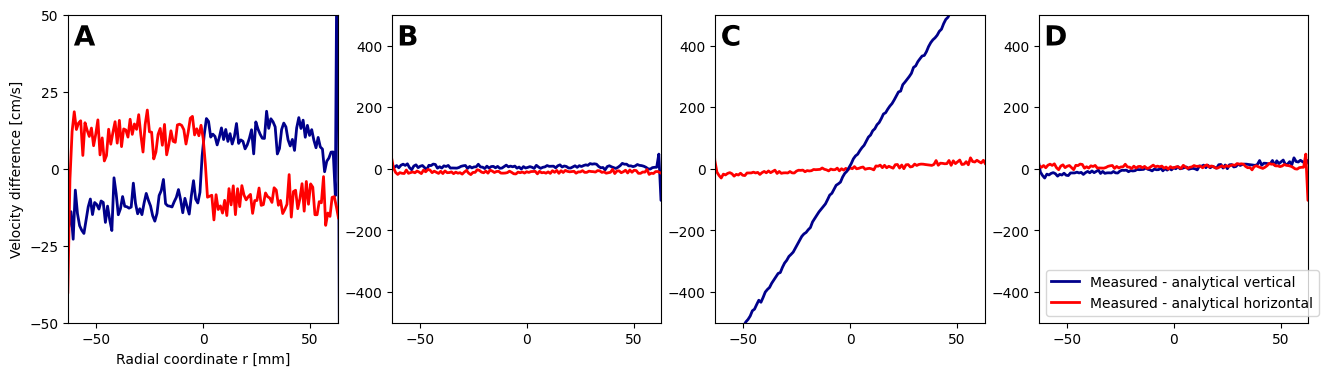

In [ ]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

# axes[0].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[0].plot(r_vec, np.abs(vely[:, center_img[0]]) - np.abs(v_analytic), color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[0].plot(r_vec2, np.abs(velx[center_img[1], :]) - np.abs(v_analytic2), color='red', linewidth=2, label='Measured - analytical  horizontal')
axes[0].set_ylim(venc_diff_lims)
axes[0].set_yticks(venc_diff_ticks)

# axes[1].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
# axes[1].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
if dir == 1:
    axes[1].plot(r_vec2, velx[center_img[1], :] + v_analytic2, color='red', linewidth=2, label='Measured - analytical horizontal')
elif dir == 2:
    axes[1].plot(r_vec2, velx[center_img[1], :] - v_analytic2, color='red', linewidth=2, label='Measured - analytical horizontal')
    
axes[1].set_ylim(venc_diff_lims)
axes[1].set_yticks(venc_diff_ticks)

# axes[2].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
# axes[2].plot(r_vec2, np.zeros_like(r_vec2), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')

axes[2].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured - analytical horizontal')
if dir == 1:
    axes[2].plot(r_vec, vely[:, center_img[0]] + v_analytic, color='darkblue', linewidth=2, label='Measured - analytical vertical')
elif dir == 2:
    axes[2].plot(r_vec, vely[:, center_img[0]] - v_analytic, color='darkblue', linewidth=2, label='Measured - analytical vertical')

axes[2].set_ylim(venc_diff_lims)
axes[2].set_yticks(venc_diff_ticks)

# axes[3].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[3].plot(r_vec2, vely[center_img[1], :], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[3].plot(r_vec, velx[:, center_img[0]], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[3].set_ylim(venc_diff_lims)
axes[3].set_yticks(venc_diff_ticks)

axes[0].set_ylabel('Velocity difference [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

plt.savefig(filename + '_veldiff' + filetype)

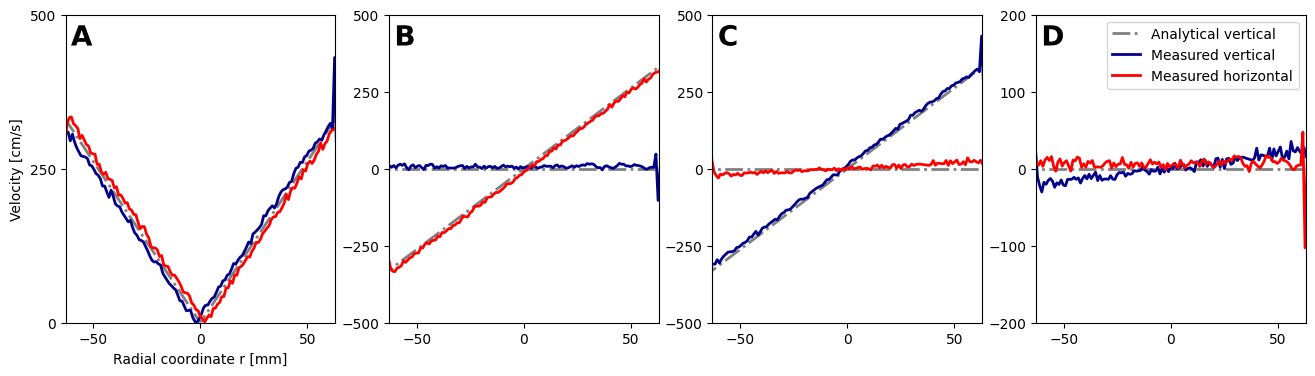

In [225]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

axes[0].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[0].plot(r_vec, np.abs(vely[:, center_img[0]]), color='darkblue', linewidth=2, label='Measured vertical')
axes[0].plot(r_vec2, np.abs(velx[center_img[1], :]), color='red', linewidth=2, label='Measured horizontal')
axes[0].set_ylim(venc_abs_lims)
axes[0].set_yticks(venc_abs_ticks)

axes[1].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[1].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[1].set_yticks(venc_ticks)

axes[2].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[2].plot(r_vec2, np.zeros_like(r_vec2), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[2].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[2].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[2].set_yticks(venc_ticks)

axes[3].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[3].plot(r_vec2, vely[center_img[1], :], color='darkblue', linewidth=2, label='Measured vertical')
axes[3].plot(r_vec, velx[:, center_img[0]], color='red', linewidth=2, label='Measured horizontal')
axes[3].set_yticks(venc_ec_ticks)
axes[3].set_ylim(venc_ec_lims)

axes[0].set_ylabel('Velocity [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

# plt.savefig(filename + '_vel' + filetype)

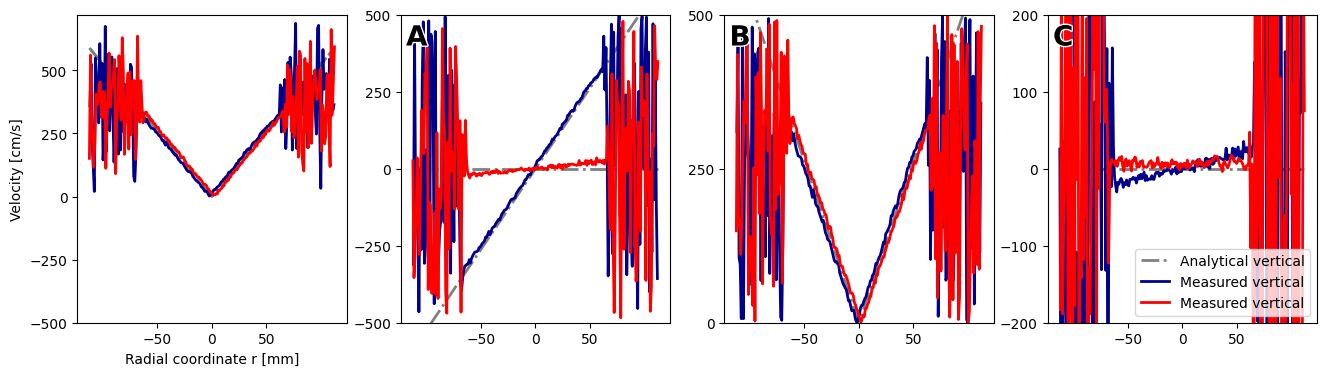

In [226]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s


X, Y = np.meshgrid(r_vec, r_vec2)
# Compute distance from the offset center
R = np.sqrt((X - center_new[0])**2 + (Y - center_new[1])**2)
mag_analytic = R <= r_phan.m_as('mm')

# mag_analytic = np.zeros_like(mag)
# mag_analytic[r_vec <= r_phan.m_as('mm'), r_vec2 <= r_phan.m_as('mm')] = 1

if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes[1:]):
    axis.set_ylim(venc_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

# axes[0].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
# axes[0].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')

# axes[0].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
# axes[0].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured vertical')
# axes[0].set_yticks(venc_ticks)



axes[0].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[0].plot(r_vec2, np.abs(v_analytic2), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')

axes[0].plot(r_vec, vel_mag[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[0].plot(r_vec2, vel_mag[center_img[1], :], color='red', linewidth=2, label='Measured vertical')
axes[0].set_yticks(venc_ticks)


# axes[0].plot(r_vec2, np.flip(mag, axis=0).diagonal() / np.max(mag[:]), color='darkblue', linewidth=2, label='Measured vertical')
# axes[0].plot(r_vec2, mag.diagonal() / np.max(mag[:]), color='red', linewidth=2, label='Measured vertical')


axes[1].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec2, np.zeros_like(r_vec2), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[1].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured vertical')
axes[1].set_yticks(venc_ticks)

axes[2].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[2].plot(r_vec, np.abs(vely[:, center_img[0]]), color='darkblue', linewidth=2, label='Measured vertical')
axes[2].plot(r_vec2, np.abs(velx[center_img[1], :]), color='red', linewidth=2, label='Measured vertical')
axes[2].set_ylim(venc_abs_lims)
axes[2].set_yticks(venc_abs_ticks)

axes[3].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[3].plot(r_vec2, vely[center_img[1], :], color='darkblue', linewidth=2, label='Measured vertical')
axes[3].plot(r_vec, velx[:, center_img[0]], color='red', linewidth=2, label='Measured vertical')
axes[3].set_yticks(venc_ec_ticks)
axes[3].set_ylim(venc_ec_lims)

axes[0].set_ylabel('Velocity [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
# axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

# for axis in axes[:-1]:
#     ticklabels = axis.get_yticklabels()
    
#     ticklabels[0] = '$\minus$venc'
#     ticklabels[-1] = 'venc'
#     axis.set_yticklabels(ticklabels)
    
# for axis in [axes[-1]]:
#     ticklabels = axis.get_yticklabels()
    
#     ticklabels[0] = '$\minus$ 10\% venc'
#     ticklabels[-1] = 'venc'
#     axis.set_yticklabels(ticklabels)